# UTS Big Data — Analisis Amazon Fashion Reviews (Amazon Reviews 2023)

# **PRADYTHA GALUH PUTRANTI**
**NIM:** 2304220013  
**Topik:** Analisis tren ulasan, produk populer, dan perbedaan rating menurut status pembelian terverifikasi.  
**Platform:** Python, PySpark, Spark SQL, Pandas, Matplotlib (dirancang untuk Google Colab).

**Catatan reproduksibilitas:** dataset diunduh dari halaman Amazon Reviews 2023 yang dikelola peneliti UC San Diego. Notebook menggunakan subset kategori *Amazon Fashion*, bukan keseluruhan katalog Amazon.


## 0. Persiapan dan kriteria penilaian

Tahapan notebook mengikuti **Extract → Transform → Load (ETL)**, lalu SQL, visualisasi, interpretasi, dan tata kelola.

Kriteria yang dibuktikan melalui output:
1. Profil volume data dan 5V.
2. Klasifikasi sumber, jenis analitik, dan pemetaan siklus hidup.
3. Pembacaan dua sumber menggunakan Spark DataFrame, menampilkan schema, jumlah baris, dan sampel.
4. Pembersihan data dengan jumlah sebelum/sesudah, minimal tiga kolom turunan, serta join dua tabel.
5. Penyimpanan Parquet berpartisi dan benchmark baca/tulis dengan CSV hasil konversi.
6. Lima query Spark SQL yang mencakup `WHERE`, `JOIN`, `GROUP BY`, `HAVING`, dan CTE `WITH`, serta dua visualisasi.
7. Perlindungan pengenal pengguna, kebijakan tata kelola, kesimpulan berbasis angka aktual, rekomendasi, dan keterbatasan.

**Penting:** sumber asli adalah JSON Lines terkompresi (`.jsonl.gz`), bukan CSV. Karena itu, perbandingan CSV vs Parquet di bagian Load adalah benchmark yang adil pada tabel ulasan bersih yang sama setelah dikonversi menjadi CSV; ini bukan perbandingan dengan file CSV asli dari penyedia data.


In [1]:
!pip -q install pyspark

import os, time, shutil, urllib.request
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F

DATA_DIR = Path("/content/amazon_fashion_data")
OUT_DIR = Path("/content/amazon_fashion_output")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

spark = (SparkSession.builder
    .appName("UTS_BigData_Amazon_Fashion")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
print("Spark version:", spark.version)

Spark version: 4.0.4


## 1. Extract — unduh dua file secara otomatis

Tahap **Extract** mengambil (1) data ulasan dan (2) metadata produk.

Data sumber berbentuk JSON Lines terkompresi. Setiap baris umumnya merepresentasikan satu objek JSON. File dibaca langsung oleh Spark; tidak perlu mengekstrak gzip secara manual terlebih dahulu.


In [2]:
REVIEW_URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/Amazon_Fashion.jsonl.gz"
META_URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/meta_categories/meta_Amazon_Fashion.jsonl.gz"
review_path = DATA_DIR / "Amazon_Fashion.jsonl.gz"
meta_path = DATA_DIR / "meta_Amazon_Fashion.jsonl.gz"

def download_if_missing(url, destination):
    if destination.exists() and destination.stat().st_size > 0:
        print(f"Sudah ada: {destination.name} ({destination.stat().st_size:,} bytes)")
        return
    print(f"Mengunduh {destination.name} ...")
    temp_destination = destination.with_suffix(destination.suffix + ".part")
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    try:
        with urllib.request.urlopen(req, timeout=300) as response, open(temp_destination, "wb") as target:
            shutil.copyfileobj(response, target)
        temp_destination.replace(destination)
    except Exception:
        if temp_destination.exists():
            temp_destination.unlink()
        raise
    print(f"Selesai: {destination.name} ({destination.stat().st_size:,} bytes)")

download_if_missing(REVIEW_URL, review_path)
download_if_missing(META_URL, meta_path)

review_bytes = review_path.stat().st_size
meta_bytes = meta_path.stat().st_size
total_source_mb = (review_bytes + meta_bytes) / (1024 ** 2)
print(f"Ulasan: {review_bytes:,} bytes")
print(f"Metadata: {meta_bytes:,} bytes")
print(f"Total sumber: {total_source_mb:.2f} MiB")
print("Total >= 100 MB (desimal):", (review_bytes + meta_bytes) >= 100_000_000)

Mengunduh Amazon_Fashion.jsonl.gz ...
Selesai: Amazon_Fashion.jsonl.gz (292,425,439 bytes)
Mengunduh meta_Amazon_Fashion.jsonl.gz ...
Selesai: meta_Amazon_Fashion.jsonl.gz (224,299,124 bytes)
Ulasan: 292,425,439 bytes
Metadata: 224,299,124 bytes
Total sumber: 492.79 MiB
Total >= 100 MB (desimal): True


## 2. Baca data dan profil awal

Data ulasan memuat atribut seperti ID produk, waktu ulasan, rating, pengenal pengguna, helpful vote, dan status pembelian terverifikasi. Metadata produk memuat atribut seperti kategori, judul, harga, rating rata-rata produk, jumlah rating, dan toko. Kolom yang benar-benar tersedia diperiksa lewat schema dan sampel output.

Schema eksplisit didefinisikan pada setidaknya satu sumber (di notebook ini keduanya). Keuntungannya: tipe kolom yang dipakai analisis ditetapkan secara konsisten, pembacaan tidak perlu menebak tipe dari sampel, dan perilaku pipeline lebih mudah direproduksi. Kekurangannya: jika struktur sumber berubah, schema perlu diperbarui; karena itu audit nilai kosong dan pemeriksaan sampel tetap diperlukan. `inferSchema` lebih praktis untuk eksplorasi, tetapi dapat menambah biaya inferensi dan berisiko salah menebak tipe pada data yang tidak konsisten.


In [3]:
from pyspark.sql import types as T

# Skema eksplisit: hanya kolom yang dibutuhkan untuk analisis.
# Ini mencegah Spark menebak tipe kolom lewat inferensi otomatis.
review_schema = T.StructType([
    T.StructField("parent_asin", T.StringType(), True),
    T.StructField("asin", T.StringType(), True),
    T.StructField("timestamp", T.LongType(), True),
    T.StructField("rating", T.DoubleType(), True),
    T.StructField("user_id", T.StringType(), True),
    T.StructField("helpful_vote", T.LongType(), True),
    T.StructField("verified_purchase", T.BooleanType(), True),
])
meta_schema = T.StructType([
    T.StructField("parent_asin", T.StringType(), True),
    T.StructField("asin", T.StringType(), True),
    T.StructField("main_category", T.StringType(), True),
    T.StructField("title", T.StringType(), True),
    T.StructField("price", T.StringType(), True),
    T.StructField("average_rating", T.DoubleType(), True),
    T.StructField("rating_number", T.LongType(), True),
    T.StructField("store", T.StringType(), True),
])

reviews_raw = spark.read.schema(review_schema).option("multiLine", "false").json(str(review_path)).cache()
meta_raw = spark.read.schema(meta_schema).option("multiLine", "false").json(str(meta_path)).cache()

review_source_rows = reviews_raw.count()
meta_source_rows = meta_raw.count()

print("Skema ulasan (ditentukan eksplisit):")
reviews_raw.printSchema()
print("Skema metadata (ditentukan eksplisit):")
meta_raw.printSchema()
print("Contoh data ulasan:")
reviews_raw.show(3, truncate=100)
print("Contoh data metadata:")
meta_raw.show(3, truncate=100)
print(f"Jumlah baris sumber ulasan: {review_source_rows:,}")
print(f"Jumlah baris sumber metadata: {meta_source_rows:,}")
print("Syarat minimal 1 juta baris:", review_source_rows >= 1_000_000)
print(f"Total ukuran sumber aktual: {total_source_mb:.2f} MiB")
print("Syarat ukuran sumber >= 100 MB:", (review_bytes + meta_bytes) >= 100_000_000)

Skema ulasan (ditentukan eksplisit):
root
 |-- parent_asin: string (nullable = true)
 |-- asin: string (nullable = true)
 |-- timestamp: long (nullable = true)
 |-- rating: double (nullable = true)
 |-- user_id: string (nullable = true)
 |-- helpful_vote: long (nullable = true)
 |-- verified_purchase: boolean (nullable = true)

Skema metadata (ditentukan eksplisit):
root
 |-- parent_asin: string (nullable = true)
 |-- asin: string (nullable = true)
 |-- main_category: string (nullable = true)
 |-- title: string (nullable = true)
 |-- price: string (nullable = true)
 |-- average_rating: double (nullable = true)
 |-- rating_number: long (nullable = true)
 |-- store: string (nullable = true)

Contoh data ulasan:
+-----------+----------+-------------+------+----------------------------+------------+-----------------+
|parent_asin|      asin|    timestamp|rating|                     user_id|helpful_vote|verified_purchase|
+-----------+----------+-------------+------+------------------------

In [4]:
# Audit nilai kosong pada kolom penting sebelum transformasi.
# Nilai null dapat berarti informasi memang tidak tersedia atau nilai tidak berhasil
# dibaca sesuai schema; audit ini bukan bukti otomatis adanya kesalahan sumber.
def null_audit(df, columns, label):
    total = df.count()
    rows = []
    for col_name in columns:
        if col_name in df.columns:
            nulls = df.filter(F.col(col_name).isNull()).count()
            rows.append((col_name, total, nulls, round(nulls / total * 100, 2) if total else 0.0))
    print(f"Audit nilai kosong — {label}")
    display(pd.DataFrame(rows, columns=["Kolom", "Total baris", "Nilai kosong", "Persen kosong"]))

null_audit(
    reviews_raw,
    ["parent_asin", "asin", "timestamp", "rating", "user_id", "helpful_vote", "verified_purchase"],
    "ulasan mentah"
)
null_audit(
    meta_raw,
    ["parent_asin", "asin", "main_category", "title", "price", "average_rating", "rating_number", "store"],
    "metadata mentah"
)


Audit nilai kosong — ulasan mentah


,Kolom,Total baris,Nilai kosong,Persen kosong
0,parent_asin,2500939,0,0.0
1,asin,2500939,0,0.0
2,timestamp,2500939,0,0.0
3,rating,2500939,0,0.0
4,user_id,2500939,0,0.0
5,helpful_vote,2500939,0,0.0
6,verified_purchase,2500939,0,0.0


Audit nilai kosong — metadata mentah


,Kolom,Total baris,Nilai kosong,Persen kosong
0,parent_asin,826108,0,0.00
1,asin,826108,826108,100.00
2,main_category,826108,0,0.00
3,title,826108,0,0.00
4,price,826108,775859,93.92
5,average_rating,826108,0,0.00
6,rating_number,826108,0,0.00
7,store,826108,26838,3.25


### 5V, konteks bisnis, dan pertanyaan bisnis

- **Volume:** notebook mencetak jumlah baris serta ukuran byte/MiB dari kedua file. Kriteria volume diperiksa dari output aktual: minimal 1.000.000 baris ulasan dan ukuran total sumber minimal 100 MB desimal. Jangan menuliskan bahwa syarat terpenuhi sebelum melihat hasil cetak.
- **Velocity:** sumber merupakan snapshot historis, bukan aliran real-time. Kolom timestamp digunakan untuk menganalisis perubahan volume ulasan dari waktu ke waktu.
- **Variety:** dua file JSON Lines semi-terstruktur berisi campuran angka, teks, ID, kategori, boolean, dan waktu.
- **Veracity:** kualitas diperiksa melalui nilai kosong, rating di luar rentang 1–5, timestamp tidak valid, ID produk kosong, duplikasi, dan kecocokan metadata. Jumlah sebelum/sesudah ditampilkan pada tahap transformasi.
- **Value:** hasil dapat membantu tim kategori dan pengalaman pelanggan menentukan produk/kategori yang perlu dipantau. Jumlah ulasan adalah sinyal keterlibatan, bukan bukti langsung jumlah penjualan atau kepuasan semua pelanggan.

**Konteks dan pengambil keputusan:** manajer kategori e-commerce dan tim pengalaman pelanggan memerlukan ringkasan untuk memprioritaskan pemeriksaan katalog, memantau perubahan umpan balik, dan menentukan area yang perlu ditinjau lebih lanjut.

**Tiga pertanyaan bisnis yang dijawab dengan SQL:**
1. Bagaimana tren jumlah ulasan dan rata-rata rating per bulan? (**Q1**, deskriptif)
2. Produk mana yang menerima ulasan terbanyak di antara produk dengan minimal 100 ulasan, dan bagaimana rating rata-ratanya? (**Q2**, deskriptif)
3. Bagaimana jumlah ulasan dan rata-rata rating berbeda menurut status pembelian terverifikasi? (**Q3**, deskriptif dengan interpretasi diagnostik awal; bukan bukti sebab-akibat)


## 3. Klasifikasi sumber, jenis analitik, dan siklus hidup data

| Sumber | Klasifikasi | Alasan |
|---|---|---|
| `Amazon_Fashion.jsonl.gz` | Semi-terstruktur | Setiap baris adalah objek JSON dengan nama atribut yang eksplisit, tetapi nilai bisa kosong dan struktur dapat bervariasi. |
| `meta_Amazon_Fashion.jsonl.gz` | Semi-terstruktur | Metadata disimpan sebagai objek JSON dengan atribut produk seperti kategori, judul, harga, dan rating. |

| Pertanyaan | Jenis analitik | Alasan |
|---|---|---|
| Q1 — tren bulanan | Deskriptif | Merangkum volume dan rata-rata rating berdasarkan bulan. |
| Q2 — produk dengan ulasan terbanyak | Deskriptif | Mengurutkan produk berdasarkan jumlah ulasan dan meringkas rating. |
| Q3 — status pembelian terverifikasi | Deskriptif / diagnostik awal | Membandingkan kelompok; perbedaan tidak menunjukkan hubungan kausal. |

**Pemetaan siklus hidup:** akuisisi sumber → validasi file/schema → profiling dan audit kualitas → pembersihan → pembuatan kolom turunan → join ulasan-metadata → penyimpanan Parquet → query SQL → visualisasi dan pelaporan → pengaturan akses, retensi, dan penghapusan.

Analitik prediktif tidak diterapkan karena notebook tidak melatih model untuk memperkirakan hasil di masa depan. Analitik preskriptif juga tidak diterapkan karena notebook tidak mengoptimalkan tindakan otomatis; rekomendasi di bagian akhir merupakan interpretasi manusia atas ringkasan deskriptif.

Timestamp sumber berupa epoch milidetik dan diubah menjadi tanggal/waktu UTC. Karena zona waktu memengaruhi batas hari/bulan, hasil waktu perlu ditafsirkan sesuai konvensi UTC yang digunakan notebook.


In [5]:
def log_rows(step_name, before_df, after_df):
    before_n = before_df.count()
    after_n = after_df.count()
    print(f"{step_name}: sebelum={before_n:,}; sesudah={after_n:,}; perubahan={after_n-before_n:+,}")
    return after_n

product_col = F.coalesce(F.col("parent_asin"), F.col("asin"))
user_col = "user_id"
timestamp_col = "timestamp"
rating_col = "rating"
helpful_col = "helpful_vote"
verified_col = "verified_purchase"

reviews_stage0 = reviews_raw.select(
    product_col.cast("string").alias("product_id"),
    F.col(timestamp_col).cast("long").alias("timestamp_epoch"),
    F.col(rating_col).cast("double").alias("rating"),
    F.col(user_col).cast("string").alias("user_id_raw"),
    F.col(helpful_col).cast("long").alias("helpful_vote"),
    F.col(verified_col).cast("string").alias("verified_purchase")
).cache()
print(f"0) Setelah memilih kolom: {reviews_stage0.count():,} baris")

reviews_stage1 = reviews_stage0.filter(F.col("product_id").isNotNull()).cache()
log_rows("1) Hapus ID produk kosong", reviews_stage0, reviews_stage1)

reviews_stage2 = reviews_stage1.filter(F.col("rating").between(1, 5)).cache()
log_rows("2) Hapus rating kosong/tidak masuk akal (di luar 1–5)", reviews_stage1, reviews_stage2)

reviews_stage3 = reviews_stage2.filter(
    F.col("timestamp_epoch").isNotNull() & (F.col("timestamp_epoch") > 0)
).cache()
log_rows("3) Hapus timestamp kosong/tidak valid", reviews_stage2, reviews_stage3)

reviews_stage4 = (reviews_stage3
    .withColumn("user_id_hash", F.when(F.col("user_id_raw").isNotNull(),
                                       F.sha2(F.col("user_id_raw"), 256)))
    .drop("user_id_raw")
    .dropDuplicates(["product_id", "timestamp_epoch", "rating", "user_id_hash"])
    .cache())
log_rows("4) Hash ID pengguna, buang ID mentah, dan hapus duplikat", reviews_stage3, reviews_stage4)

# Catat kualitas nilai yang diperbaiki tanpa membuang baris.
rows_before_value_cleanup = reviews_stage4.count()
bad_helpful_count = reviews_stage4.filter(
    F.col("helpful_vote").isNull() | (F.col("helpful_vote") < 0)
).count()
missing_verified_count = reviews_stage4.filter(F.col("verified_purchase").isNull()).count()
print(f"5a) Perbaikan helpful_vote: baris sebelum={rows_before_value_cleanup:,}; "
      f"baris sesudah tetap={rows_before_value_cleanup:,}; nilai kosong/negatif diubah ke 0={bad_helpful_count:,}")
print(f"5b) Perbaikan verified_purchase: baris sebelum={rows_before_value_cleanup:,}; "
      f"baris sesudah tetap={rows_before_value_cleanup:,}; nilai kosong diubah ke 'unknown'={missing_verified_count:,}")

reviews = (reviews_stage4
    .withColumn("review_timestamp", F.to_timestamp(F.from_unixtime(F.col("timestamp_epoch") / 1000)))
    .withColumn("review_date", F.to_date("review_timestamp"))
    .withColumn("review_year_month", F.date_format("review_timestamp", "yyyy-MM"))
    .withColumn("review_year", F.year("review_timestamp"))
    .withColumn("rating_group", F.when(F.col("rating") >= 4, "Tinggi (4–5)")
                                .when(F.col("rating") >= 3, "Sedang (3)")
                                .otherwise("Rendah (1–2)"))
    .withColumn("helpful_vote", F.when(F.col("helpful_vote").isNull() |
                                       (F.col("helpful_vote") < 0), 0)
                                .otherwise(F.col("helpful_vote")).cast("long"))
    .withColumn("verified_purchase", F.coalesce(F.col("verified_purchase"), F.lit("unknown")))
    .drop("timestamp_epoch")
    .cache())

print(f"5) Jumlah ulasan bersih akhir: {reviews.count():,}")
print("Kolom turunan: review_timestamp, review_date, review_year_month, review_year, rating_group.")
print("Nilai helpful_vote kosong/negatif menjadi 0; status pembelian kosong menjadi 'unknown'.")
reviews.printSchema()
reviews.show(5, truncate=False)

0) Setelah memilih kolom: 2,500,939 baris
1) Hapus ID produk kosong: sebelum=2,500,939; sesudah=2,500,939; perubahan=+0
2) Hapus rating kosong/tidak masuk akal (di luar 1–5): sebelum=2,500,939; sesudah=2,500,939; perubahan=+0
3) Hapus timestamp kosong/tidak valid: sebelum=2,500,939; sesudah=2,500,939; perubahan=+0
4) Hash ID pengguna, buang ID mentah, dan hapus duplikat: sebelum=2,500,939; sesudah=2,475,694; perubahan=-25,245
5a) Perbaikan helpful_vote: baris sebelum=2,475,694; baris sesudah tetap=2,475,694; nilai kosong/negatif diubah ke 0=0
5b) Perbaikan verified_purchase: baris sebelum=2,475,694; baris sesudah tetap=2,475,694; nilai kosong diubah ke 'unknown'=0
5) Jumlah ulasan bersih akhir: 2,475,694
Kolom turunan: review_timestamp, review_date, review_year_month, review_year, rating_group.
Nilai helpful_vote kosong/negatif menjadi 0; status pembelian kosong menjadi 'unknown'.
root
 |-- product_id: string (nullable = true)
 |-- rating: double (nullable = true)
 |-- helpful_vote: lo

## 4. Transform — pembersihan, kolom turunan, dan JOIN

Transformasi menyiapkan data agar dapat dianalisis secara konsisten. ID produk dipilih dari `parent_asin` dan, jika kosong, menggunakan `asin`. Baris tanpa ID produk, rating di luar 1–5, serta timestamp kosong/tidak valid dihapus karena tidak dapat mendukung analisis utama. Duplikat dihapus menggunakan kombinasi ID produk, timestamp, rating, dan hash ID pengguna.

ID pengguna di-hash dengan SHA-256 dan kolom mentah dibuang. Hash adalah **pseudonimisasi**, bukan anonimisasi sempurna. Nilai helpful vote kosong/negatif dinormalisasi menjadi 0 dan status pembelian kosong ditandai `unknown`; perubahan ini mempertahankan baris sambil mendokumentasikan asumsi yang digunakan.

Kolom turunan mencakup `review_timestamp`, `review_date`, `review_year_month`, `review_year`, dan `rating_group`. Kolom waktu mendukung agregasi tren, sedangkan `rating_group` memudahkan segmentasi rating.

Metadata dibersihkan dari ID produk kosong dan duplikat ID produk. `LEFT JOIN` dipakai agar semua ulasan bersih tetap dipertahankan walaupun metadata produk tidak ditemukan. Tingkat kecocokan dihitung menggunakan kolom judul metadata yang terisi; metrik ini adalah proksi kecocokan, bukan bukti bahwa seluruh atribut metadata lengkap.


In [6]:
meta_product_col = "parent_asin"
meta_category_col = "main_category"
meta_title_col = "title"
meta_price_col = "price"
meta_avg_col = "average_rating"
meta_count_col = "rating_number"
meta_store_col = "store"

meta_stage0 = meta_raw.select(
    F.coalesce(F.col("parent_asin"), F.col("asin")).cast("string").alias("product_id"),
    F.col(meta_category_col).cast("string").alias("main_category"),
    F.col(meta_title_col).cast("string").alias("product_title"),
    F.col(meta_price_col).cast("string").alias("price_raw"),
    F.col(meta_avg_col).cast("double").alias("product_average_rating"),
    F.col(meta_count_col).cast("long").alias("product_rating_count"),
    F.col(meta_store_col).cast("string").alias("store")
).cache()

products_stage1 = meta_stage0.filter(F.col("product_id").isNotNull()).cache()
log_rows("Metadata 1) Hapus ID produk kosong", meta_stage0, products_stage1)

products = products_stage1.dropDuplicates(["product_id"]).cache()
log_rows("Metadata 2) Hapus duplikat ID produk", products_stage1, products)

# LEFT JOIN mempertahankan semua ulasan bersih walaupun metadata produk tidak ditemukan.
joined = reviews.join(products, on="product_id", how="left").cache()
joined_rows = joined.count()
matched_rows = joined.filter(F.col("product_title").isNotNull()).count()
match_pct = (100 * matched_rows / joined_rows) if joined_rows else 0

print(f"Jumlah ulasan bersih: {reviews.count():,}")
print(f"Jumlah produk metadata bersih: {products.count():,}")
print(f"Jumlah baris hasil LEFT JOIN: {joined_rows:,}")
print(f"Ulasan dengan pasangan metadata: {matched_rows:,} ({match_pct:.2f}%)")
print("Alasan LEFT JOIN: semua ulasan dipertahankan, termasuk yang metadata-nya tidak cocok.")
joined.select("product_id", "rating", "review_year_month", "main_category", "product_title").show(5, truncate=80)

Metadata 1) Hapus ID produk kosong: sebelum=826,108; sesudah=826,108; perubahan=+0
Metadata 2) Hapus duplikat ID produk: sebelum=826,108; sesudah=826,108; perubahan=+0
Jumlah ulasan bersih: 2,475,694
Jumlah produk metadata bersih: 826,108
Jumlah baris hasil LEFT JOIN: 2,475,694
Ulasan dengan pasangan metadata: 2,475,694 (100.00%)
Alasan LEFT JOIN: semua ulasan dipertahankan, termasuk yang metadata-nya tidak cocok.
+----------+------+-----------------+--------------+--------------------------------------------------------------------------------+
|product_id|rating|review_year_month| main_category|                                                                   product_title|
+----------+------+-----------------+--------------+--------------------------------------------------------------------------------+
|0512238987|   3.0|          2022-10|AMAZON FASHION|Womens Cap Sleeve Crew Neck Tshirts with Pocket Summer Casual Leopard Loose F...|
|0512239150|   5.0|          2022-06|AMAZON FA

## 5. Load — simpan hasil ETL ke Parquet dan bandingkan format


In [7]:
reviews_parquet = OUT_DIR / "reviews_clean_parquet"
products_parquet = OUT_DIR / "products_clean_parquet"
joined_parquet = OUT_DIR / "reviews_products_joined_parquet"
reviews_csv = OUT_DIR / "reviews_clean_csv_benchmark"

def folder_size_bytes(folder):
    return sum(os.path.getsize(os.path.join(root, name))
               for root, _, files in os.walk(folder) for name in files)

t0 = time.time()
reviews.write.mode("overwrite").partitionBy("review_year_month").parquet(str(reviews_parquet))
products.write.mode("overwrite").parquet(str(products_parquet))
joined.write.mode("overwrite").partitionBy("review_year_month").parquet(str(joined_parquet))
parquet_write_seconds = time.time() - t0

# CSV benchmark dibuat dari tabel ulasan bersih yang sama, bukan sumber mentah.
t0 = time.time()
reviews.write.mode("overwrite").option("header", True).csv(str(reviews_csv))
csv_write_seconds = time.time() - t0

parquet_bytes = folder_size_bytes(reviews_parquet)
csv_bytes = folder_size_bytes(reviews_csv)

# Hitung semua baris agar Spark benar-benar membaca data, bukan hanya membangun rencana.
t0 = time.time()
parquet_read_rows = spark.read.parquet(str(reviews_parquet)).count()
parquet_read_seconds = time.time() - t0

t0 = time.time()
csv_check = (spark.read.schema(reviews.schema)
             .option("header", True)
             .option("dateFormat", "yyyy-MM-dd")
             .csv(str(reviews_csv)))
csv_read_rows = csv_check.count()
csv_read_seconds = time.time() - t0

benchmark = pd.DataFrame([
    {"Format": "CSV hasil konversi", "Ukuran (MiB)": round(csv_bytes/1024**2, 2),
     "Waktu baca + count (detik)": round(csv_read_seconds, 2), "Baris terbaca": csv_read_rows},
    {"Format": "Parquet", "Ukuran (MiB)": round(parquet_bytes/1024**2, 2),
     "Waktu baca + count (detik)": round(parquet_read_seconds, 2), "Baris terbaca": parquet_read_rows},
])
display(benchmark)

print(f"Waktu tulis Parquet (tiga tabel): {parquet_write_seconds:.2f} detik")
print(f"Waktu tulis CSV benchmark: {csv_write_seconds:.2f} detik")
print("Ukuran Parquet metadata (MiB):", round(folder_size_bytes(products_parquet)/1024**2, 2))
print("Ukuran Parquet hasil join (MiB):", round(folder_size_bytes(joined_parquet)/1024**2, 2))
print("Baris CSV dan Parquet sama:", csv_read_rows == parquet_read_rows == reviews.count())

,Format,Ukuran (MiB),Waktu baca + count (detik),Baris terbaca
0,CSV hasil konversi,358.54,1.91,2475694
1,Parquet,209.84,8.64,2475694


Waktu tulis Parquet (tiga tabel): 76.77 detik
Waktu tulis CSV benchmark: 8.84 detik
Ukuran Parquet metadata (MiB): 56.43
Ukuran Parquet hasil join (MiB): 343.07
Baris CSV dan Parquet sama: True


## 6. Lima query Spark SQL

DataFrame didaftarkan sebagai temporary view sehingga dapat dianalisis dengan Spark SQL. Lima query di bawah mencakup `WHERE` (filter), `JOIN` (penggabungan), `GROUP BY` (agregasi), `HAVING` (filter setelah agregasi), dan CTE `WITH` (subquery bernama).

- **Q1:** tren bulanan untuk menjawab pertanyaan bisnis 1.
- **Q2:** produk dengan minimal 100 ulasan, diurutkan berdasarkan volume, untuk menjawab pertanyaan bisnis 2.
- **Q3:** perbandingan status pembelian terverifikasi untuk menjawab pertanyaan bisnis 3.
- **Q4:** ringkasan volume dan rating per kategori dari hasil join.
- **Q5:** contoh agregasi ulasan yang digabung dengan metadata produk.

Ambang `100` pada Q2 dan `1.000` pada Q4 adalah batas analisis agar perbandingan berfokus pada grup dengan volume memadai, bukan ambang kualitas produk. Periksa hasil aktual sebelum menyusun kesimpulan.


In [8]:
reviews.createOrReplaceTempView("reviews")
products.createOrReplaceTempView("products")
joined.createOrReplaceTempView("reviews_products")

# Q1 — CTE + GROUP BY: tren bulanan
q1 = spark.sql("""
WITH monthly AS (
  SELECT review_year_month, COUNT(*) AS review_count, ROUND(AVG(rating), 3) AS avg_rating
  FROM reviews
  WHERE review_year_month IS NOT NULL
  GROUP BY review_year_month
)
SELECT * FROM monthly ORDER BY review_year_month
""")
q1.show(100, truncate=False)

# Q2 — GROUP BY + HAVING: produk dengan setidaknya 100 ulasan
q2 = spark.sql("""
SELECT product_id, COUNT(*) AS review_count, ROUND(AVG(rating), 3) AS avg_rating,
       SUM(helpful_vote) AS total_helpful_votes
FROM reviews
GROUP BY product_id
HAVING COUNT(*) >= 100
ORDER BY review_count DESC
LIMIT 20
""")
q2.show(20, truncate=False)

# Q3 — WHERE + GROUP BY: status pembelian terverifikasi
q3 = spark.sql("""
SELECT verified_purchase, COUNT(*) AS review_count, ROUND(AVG(rating), 3) AS avg_rating
FROM reviews
WHERE verified_purchase IS NOT NULL
GROUP BY verified_purchase
ORDER BY review_count DESC
""")
q3.show(truncate=False)

# Q4 — JOIN + GROUP BY + HAVING: kategori dengan cukup banyak ulasan
q4 = spark.sql("""
SELECT COALESCE(main_category, 'Unknown') AS category, COUNT(*) AS review_count,
       ROUND(AVG(rating), 3) AS avg_rating, COUNT(DISTINCT product_id) AS distinct_products
FROM reviews_products
GROUP BY COALESCE(main_category, 'Unknown')
HAVING COUNT(*) >= 1000
ORDER BY review_count DESC
LIMIT 20
""")
q4.show(20, truncate=False)

# Q5 — CTE + JOIN + WHERE + GROUP BY + HAVING: produk populer dengan metadata
q5 = spark.sql("""
WITH review_agg AS (
  SELECT product_id, COUNT(*) AS review_count, ROUND(AVG(rating), 3) AS avg_review_rating
  FROM reviews
  WHERE rating BETWEEN 1 AND 5
  GROUP BY product_id
  HAVING COUNT(*) >= 50
)
SELECT r.product_id, p.product_title, p.main_category, r.review_count,
       r.avg_review_rating, p.product_average_rating
FROM review_agg r INNER JOIN products p ON r.product_id = p.product_id
WHERE p.product_title IS NOT NULL
ORDER BY r.review_count DESC
LIMIT 25
""")
q5.show(25, truncate=100)

+-----------------+------------+----------+
|review_year_month|review_count|avg_rating|
+-----------------+------------+----------+
|2002-05          |1           |5.0       |
|2002-07          |1           |5.0       |
|2002-09          |1           |5.0       |
|2002-10          |1           |5.0       |
|2002-11          |1           |5.0       |
|2002-12          |1           |4.0       |
|2003-03          |2           |4.5       |
|2003-05          |1           |5.0       |
|2003-06          |1           |4.0       |
|2003-07          |2           |5.0       |
|2003-10          |1           |5.0       |
|2003-12          |3           |4.0       |
|2004-01          |1           |5.0       |
|2004-02          |4           |3.75      |
|2004-03          |2           |4.5       |
|2004-04          |2           |4.5       |
|2004-05          |4           |4.25      |
|2004-06          |3           |3.333     |
|2004-07          |7           |3.857     |
|2004-08          |2           |

## 7. Visualisasi

Grafik pertama memperlihatkan jumlah ulasan per bulan agar lonjakan atau penurunan volume mudah terlihat. Grafik kedua memperlihatkan 15 produk dengan jumlah ulasan terbanyak dari hasil Q2. Grafik digunakan untuk eksplorasi dan komunikasi hasil, bukan untuk menyimpulkan penyebab tren.

Hanya hasil agregasi berukuran kecil yang dikonversi ke Pandas. Mengonversi seluruh dataset besar ke Pandas dapat membebani memori driver.


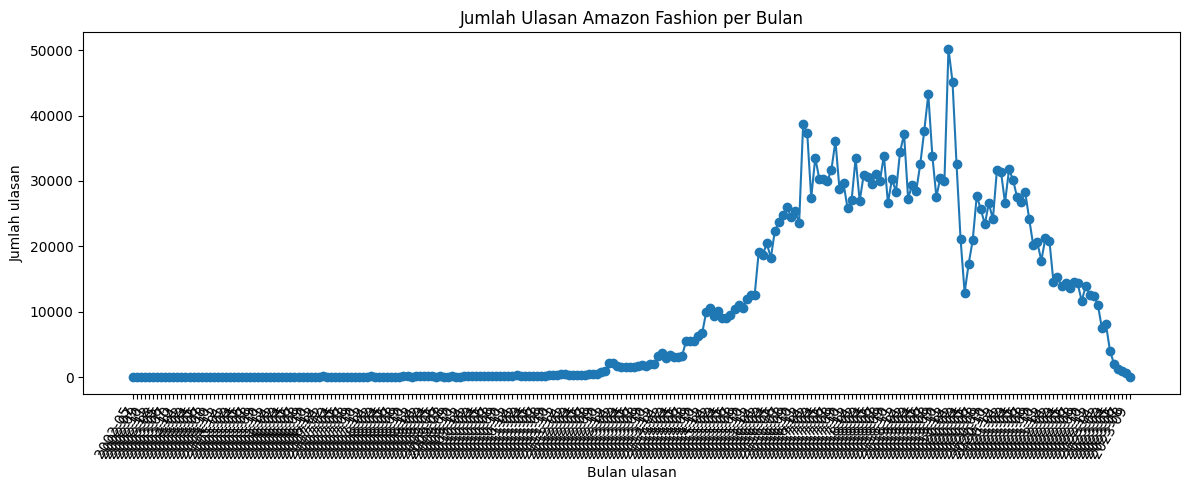

In [9]:
monthly_pd = q1.orderBy("review_year_month").toPandas()
if not monthly_pd.empty:
    plt.figure(figsize=(12, 5))
    plt.plot(monthly_pd["review_year_month"], monthly_pd["review_count"], marker="o")
    plt.title("Jumlah Ulasan Amazon Fashion per Bulan")
    plt.xlabel("Bulan ulasan")
    plt.ylabel("Jumlah ulasan")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada data bulanan untuk divisualisasikan.")

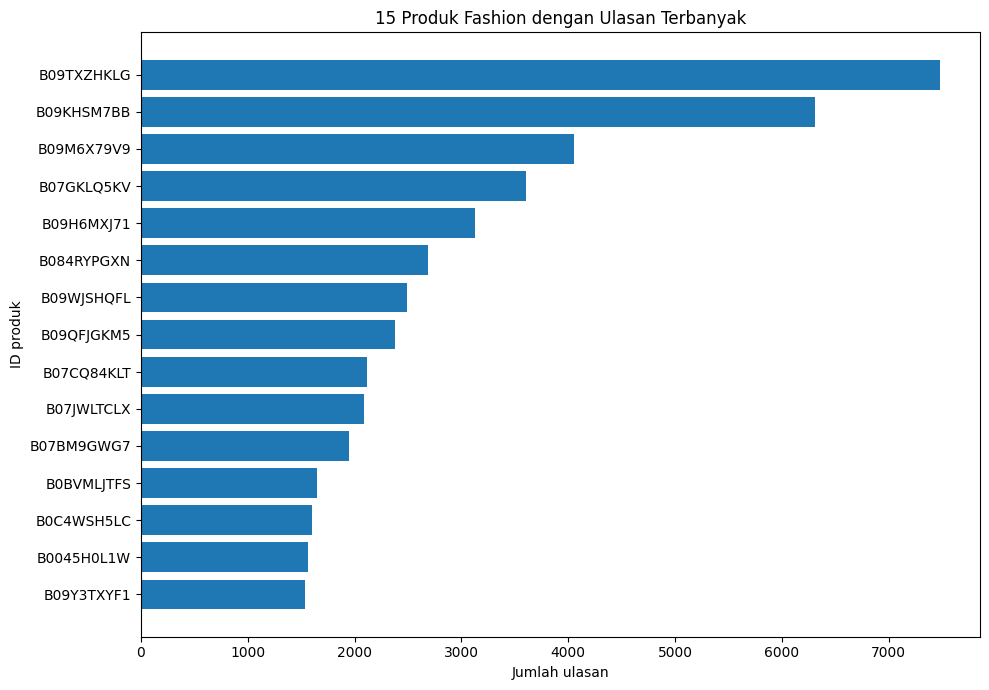

In [10]:
top_pd = q2.orderBy(F.desc("review_count")).limit(15).toPandas()
if not top_pd.empty:
    top_pd["product_label"] = top_pd["product_id"].astype(str)
    plt.figure(figsize=(10, 7))
    plt.barh(top_pd["product_label"][::-1], top_pd["review_count"][::-1])
    plt.title("15 Produk Fashion dengan Ulasan Terbanyak")
    plt.xlabel("Jumlah ulasan")
    plt.ylabel("ID produk")
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada produk yang memenuhi ambang minimal 100 ulasan.")

## 8. Etika, privasi, tata kelola, dan keterbatasan

- **Pengenal pengguna:** `user_id` adalah pengenal yang berpotensi mengidentifikasi seseorang. Notebook menerapkan SHA-256, kemudian membuang ID mentah. Hash tetap pseudonim; aksesnya tetap perlu dibatasi.
- **Potensi sensitif saat digabung:** teks ulasan, ID produk, waktu, dan toko mungkin memungkinkan pengaitan dengan informasi lain. Teks ulasan penuh tidak dipakai pada tabel analisis utama karena tidak diperlukan untuk pertanyaan bisnis.
- **Minimisasi data:** hanya kolom yang relevan dipilih untuk analisis. Jangan mempublikasikan data baris-per-baris atau pengenal pseudonim.
- **Kualitas dan bias:** pengulas bersifat sukarela dan tidak mewakili semua pembeli. Nilai kosong tidak selalu berarti kesalahan; bisa berarti informasi tidak tersedia. Normalisasi helpful vote menjadi 0 adalah asumsi analitis yang perlu disebutkan.
- **Akses:** batasi data mentah dan output pada penyusun dan penilai yang berwenang; gunakan folder dengan izin akses sesuai kebutuhan.
- **Retensi:** simpan salinan kerja hanya selama pengerjaan dan penilaian, maksimal 90 hari setelah nilai final, lalu hapus salinan yang tidak lagi diperlukan sesuai kebijakan institusi.
- **Risiko kebocoran:** data pseudonim bisa dicocokkan dengan sumber eksternal; output juga dapat disalahgunakan untuk membuat kesimpulan berlebihan tentang perilaku pelanggan.
- **Keterbatasan teknis:** harga disimpan sebagai teks karena formatnya bisa bervariasi dan tidak digunakan sebagai metrik numerik sebelum dibersihkan. Benchmark CSV–Parquet adalah pengukuran pada satu lingkungan. Jumlah ulasan bukan jumlah penjualan, data historis bukan streaming, dan analisis deskriptif tidak membuktikan sebab-akibat.


## 9. Kesimpulan, insight, dan rekomendasi berbasis hasil aktual

Sel berikut mengambil hasil langsung dari query Spark agar angka kesimpulan tidak diketik berdasarkan perkiraan. Jalankan seluruh notebook terlebih dahulu. Gunakan hasil cetak sebagai jawaban akhir untuk tiga pertanyaan bisnis.

**Cara membaca insight:**
1. Q1: bulan dengan volume ulasan tertinggi menunjukkan puncak aktivitas ulasan, bukan otomatis puncak penjualan.
2. Q2: produk teratas layak diprioritaskan untuk pemeriksaan stok/katalog dan pembacaan ulasan lebih lanjut; volume tinggi tidak selalu berarti rating terbaik.
3. Q3: perbedaan rata-rata rating menurut status pembelian adalah asosiasi deskriptif. Jangan menyatakan status verifikasi menyebabkan rating lebih tinggi/rendah.

**Rekomendasi:** (1) pantau tren volume dan rating per bulan; (2) tinjau produk ber-volume tinggi dengan menggabungkan rating, ulasan teks, dan data operasional yang sah; (3) investigasi perbedaan rating antarstatus pembelian dengan kontrol faktor lain sebelum membuat kebijakan. Nyatakan setidaknya satu keterbatasan, misalnya bias ulasan sukarela dan tidak adanya data transaksi penjualan.


In [11]:
summary = {
    "review_rows_source": review_source_rows,
    "metadata_rows_source": meta_source_rows,
    "review_source_size_MiB": round(review_bytes / (1024**2), 2),
    "metadata_source_size_MiB": round(meta_bytes / (1024**2), 2),
    "total_source_size_MiB": round(total_source_mb, 2),
    "review_rows_clean": reviews.count(),
    "product_rows_clean": products.count(),
    "joined_rows": joined_rows,
    "metadata_match_percent": round(match_pct, 2),
    "csv_size_MiB": round(csv_bytes / (1024**2), 2),
    "parquet_size_MiB": round(parquet_bytes / (1024**2), 2),
    "csv_read_seconds": round(csv_read_seconds, 2),
    "parquet_read_seconds": round(parquet_read_seconds, 2),
    "parquet_write_seconds": round(parquet_write_seconds, 2),
}
display(pd.DataFrame([{"Metrik": k, "Nilai aktual": v} for k, v in summary.items()]))

peak_month = q1.orderBy(F.desc("review_count")).first()
top_product = q2.orderBy(F.desc("review_count")).first()
q3_nonempty = q3.filter(F.col("avg_rating").isNotNull())
best_group = q3_nonempty.orderBy(F.desc("avg_rating")).first()
lowest_group = q3_nonempty.orderBy(F.asc("avg_rating")).first()

print("\nJAWABAN 3 PERTANYAAN BISNIS")
if peak_month:
    print(f"1. Bulan dengan ulasan terbanyak: {peak_month['review_year_month']} — "
          f"{peak_month['review_count']:,} ulasan; rata-rata rating {peak_month['avg_rating']}.")
else:
    print("1. Belum ada hasil tren bulanan.")

if top_product:
    print(f"2. Produk dengan ulasan terbanyak di antara produk yang memenuhi ambang Q2: "
          f"{top_product['product_id']} — {top_product['review_count']:,} ulasan; "
          f"rata-rata rating {top_product['avg_rating']}.")
else:
    print("2. Tidak ada produk yang memenuhi ambang minimal 100 ulasan.")

if best_group and lowest_group:
    print(f"3. Rating rata-rata tertinggi: status '{best_group['verified_purchase']}' "
          f"({best_group['avg_rating']}, {best_group['review_count']:,} ulasan); "
          f"terendah: status '{lowest_group['verified_purchase']}' "
          f"({lowest_group['avg_rating']}, {lowest_group['review_count']:,} ulasan).")
else:
    print("3. Belum ada kelompok status pembelian yang dapat dibandingkan.")

print("\nMINIMAL TIGA REKOMENDASI TINDAKAN")
print("1. Pantau bulan dengan volume ulasan tertinggi dan bandingkan dengan rata-rata rating bulan tersebut.")
if top_product:
    print(f"2. Tinjau katalog dan umpan balik produk {top_product['product_id']} karena memiliki volume ulasan tertinggi pada Q2.")
else:
    print("2. Tinjau produk yang memenuhi ambang jumlah ulasan setelah hasil Q2 diperiksa.")
if best_group and lowest_group:
    print("3. Selidiki perbedaan rating antarstatus pembelian lebih lanjut; jangan menyimpulkan hubungan sebab-akibat dari perbandingan deskriptif saja.")
else:
    print("3. Gunakan Q4 untuk memprioritaskan kategori dengan jumlah ulasan memadai.")
print("Keterbatasan utama: ulasan bersifat sukarela dan tidak mewakili seluruh pembeli; analisis deskriptif tidak membuktikan sebab-akibat.")

,Metrik,Nilai aktual
0,review_rows_source,2500939.00
1,metadata_rows_source,826108.00
2,review_source_size_MiB,278.88
3,metadata_source_size_MiB,213.91
4,total_source_size_MiB,492.79
5,review_rows_clean,2475694.00
6,product_rows_clean,826108.00
7,joined_rows,2475694.00
8,metadata_match_percent,100.00
9,csv_size_MiB,358.54



JAWABAN 3 PERTANYAAN BISNIS
1. Bulan dengan ulasan terbanyak: 2019-12 — 50,214 ulasan; rata-rata rating 4.06.
2. Produk dengan ulasan terbanyak di antara produk yang memenuhi ambang Q2: B09TXZHKLG — 7,480 ulasan; rata-rata rating 4.411.
3. Rating rata-rata tertinggi: status 'true' (3.971, 2,314,072 ulasan); terendah: status 'false' (3.958, 161,622 ulasan).

MINIMAL TIGA REKOMENDASI TINDAKAN
1. Pantau bulan dengan volume ulasan tertinggi dan bandingkan dengan rata-rata rating bulan tersebut.
2. Tinjau katalog dan umpan balik produk B09TXZHKLG karena memiliki volume ulasan tertinggi pada Q2.
3. Selidiki perbedaan rating antarstatus pembelian lebih lanjut; jangan menyimpulkan hubungan sebab-akibat dari perbandingan deskriptif saja.
Keterbatasan utama: ulasan bersifat sukarela dan tidak mewakili seluruh pembeli; analisis deskriptif tidak membuktikan sebab-akibat.
